In [4]:
# Imports
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
# PART A: DATA ACQUISITION & PREPROCESSING
# Load datasets
orders = pd.read_csv("archive/olist_orders_dataset.csv")
items = pd.read_csv("archive/olist_order_items_dataset.csv")
products = pd.read_csv("archive/olist_products_dataset.csv")
customers = pd.read_csv("archive/olist_customers_dataset.csv")
payments = pd.read_csv("archive/olist_order_payments_dataset.csv")
reviews = pd.read_csv("archive/olist_order_reviews_dataset.csv")
product_cat = pd.read_csv("archive/product_category_name_translation.csv")

# --- Preprocessing for Association Rule Mining: Create Basket Table ---

# Merge for product names
basket_data = items.merge(products, on='product_id', how='left')
basket_data = basket_data.merge(product_cat, on='product_category_name', how='left')
basket_data['product_name'] = basket_data['product_category_name_english'].fillna(basket_data['product_category_name'])

# One-hot encoded basket
basket = basket_data.groupby(['order_id', 'product_name'])['order_item_id'].count().unstack().fillna(0)
basket = basket.gt(0).astype(int)

# **PART C: Market Basket Analysis**

In [39]:
# PART C: MARKET BASKET ANALYSIS

#MLxtend (Machine learning extensions) is a Python library that is used for data science tasks (Raschka, 2014).
#This import will be used for the market basket analysis.
from mlxtend.frequent_patterns import apriori, association_rules

#This line helps identify the 15 most frequently purchased product categories from the 'basket' dataframe.
#To do this, 'sum()' was used to add each column in the 'basket' dataframe and sort them in descending order using 'sort_values()'.
#Only 15 columns were stored in 'top_products' out of 73 columns in 'basket.'
top_products = basket.sum().sort_values(ascending=False).head(15).index

#This creates a new data frame, 'basket_top' from the columns stored in 'top_products.'
#This helps filter the original basket to only focus on the most frequent product categories that will be used for market basket analysis later.
basket_top = basket[top_products]

#This line filters the 'basket_top' to include only rows or the transactions that bought at least two (2) of the 15 products.
#The function 'astype(bool)' is to convert these values to boolean as they were originally integers.
#This is needed as the Apriori algorithm as they mine frequent itemset for Boolean association rules (Han et al., 2012, pp. 243–278).
basket_top = basket_top[basket_top.sum(axis=1) >= 2].astype(bool)

#This line executes the Apriori algorithm to find frequent itemsets.
#A 'min_support' of 0.001 is set, wherein at least 0.1% of transactions is considered for an itemset to be frequent.
#In this dataset, co-occurrence is very rare, this is why around 100 orders is set to be the minimum support.
#The use of 'use_colname=True' is for ensuring the resulting itemsets will used the product names instead of column indices.
frequent_itemsets = apriori(basket_top, min_support=0.001, use_colnames=True)

#This line prints the total number of frequent itemsets discovered by the Apriori algorithm. 
#'frequent_itemsets.shape[0]' accesses the number of rows in the frequent_itemsets DataFrame, where each row represents a unique frequent itemset.
print("Total Frequent Itemsets:", frequent_itemsets.shape[0])

#This generates association rules from the 'frequent_itemset', and a min_threshold of 0.1 was set for our dispersed data to capture rules but still filter noise.
#Association rule finds the associations among the sets of data (GeeksforGeeks, 2018).
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.1)

Total Frequent Itemsets: 101


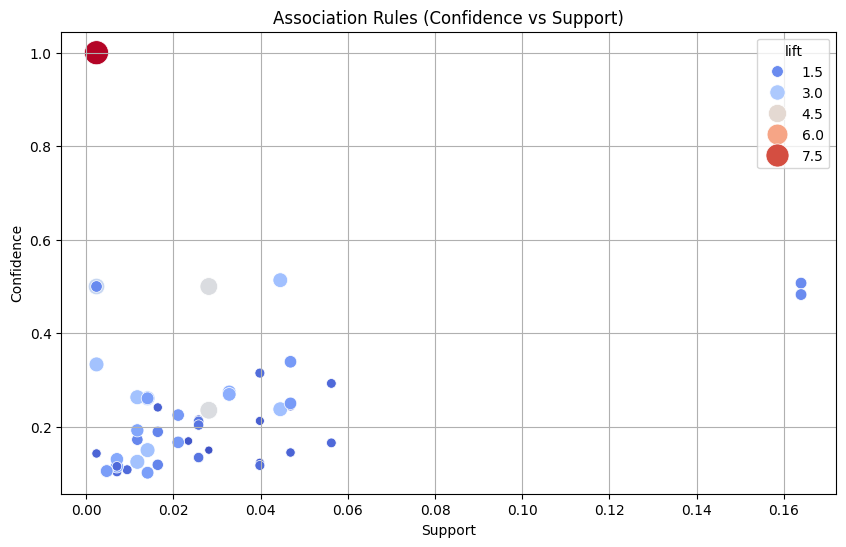

In [38]:
#This line initiates a new figure for plotting, and figsize=(10, 6) sets the dimensions of this figure to 10 inches wide by 6 inches high. 
#This provides a suitable canvas for the upcoming scatter plot, ensuring good visibility of the data points.
plt.figure(figsize=(10, 6))
#This uses Seaborn to generate a scatter plot to visualize the relationship between 'support' and 'confidence' of the association rules.
#The size and hue of the points are mapped to the 'lift' metric, allowing for a visual representation of the strength and interestingness of each rule, with point sizes ranging from 30 to 300 and a 'coolwarm' color palette.
sns.scatterplot(data=rules,
                x='support',
                y='confidence',
                size='lift',
                hue='lift',
                sizes=(30, 300),
                palette='coolwarm')
#This line sets the title of the scatter plot to "Association Rules (Confidence vs Support)". 
#This title clearly indicates what the plot represents for context of the visualization.
plt.title("Association Rules (Confidence vs Support)")
#This line labels the x-axis of the plot as "Support". 
#The support metric indicates how frequently an itemset appears in the dataset, providing context for the horizontal axis (GeeksforGeeks, 2019).
plt.xlabel("Support")
#This line labels the y-axis of the plot as "Confidence". 
#The confidence metric measures how often items in the consequent appear given the presence of items in the antecedent, clarifying the meaning of the vertical axis (GeeksforGeeks, 2019).
plt.ylabel("Confidence")
#This line adds a grid to the plot background. 
#The grid lines enhance readability by making it easier to estimate the values of data points on both the x and y axes.
plt.grid(True)
#This line displays the generated scatter plot. 
#This renders the plot to make it visible to the user.
plt.show()

In [22]:
#This sorts the 'rules' dataframe in descending order by the lift metric, wherein the top 5 rules are retrieved.
#Only the columns 'antecedents', 'consequents', 'support', 'confidence', 'lift' were selected to view for later.
top_rules = rules.sort_values(by='lift', ascending=False)[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(5)

# Convert frozensets to strings
#Since the mlxtend stores the antecedents in frozenset, they need to be converted into strings.
#This loops over each frozenset in 'antecedent' and joining them with commas to make them readable.
top_rules['antecedents'] = top_rules['antecedents'].apply(lambda x: ', '.join(list(x)))

#Since the mlxtend stores the consequents in frozenset, they need to be converted into strings.
#This loops over each frozenset in 'consequents' and joining them with commas to make them readable.
top_rules['consequents'] = top_rules['consequents'].apply(lambda x: ', '.join(list(x)))

#This simply resets the index of the dataframe, with drop preventing the old index to be added as a new column.
#This helps for a clean and sequential index for the top 5 association rules.
top_rules.reset_index(drop=True, inplace=True)

#This line simply displays the top_rules DataFrame. 
#After all the sorting, selection, and formatting, this command outputs the final table containing the top 5 association rules for analysis and interpretation.
top_rules

,antecedents,consequents,support,confidence,lift
0,"health_beauty, computers_accessories",sports_leisure,0.002342,1.000000,8.211538
1,health_beauty,perfumery,0.028103,0.235294,4.186275
2,perfumery,health_beauty,0.028103,0.500000,4.186275
3,"bed_bath_table, auto",cool_stuff,0.002342,0.500000,3.618644
4,electronics,computers_accessories,0.011710,0.263158,2.809211


# **Part D: Reinforcement Learning: Conceptual Demonstration**

## **Research on Reinforcement Learning:**  
Reinforcement Learning (RL) comes alongside Supervised and Unsupervised learning techniques, which mainly focus on agency through trial and error (GeeksforGeeks, 2018a).  This machine learning occurs with an interaction with the environment to reach a goal, receiving feedback of either a reward or a penalty depending on their actions. Through the reinforced feedback, the machine learns over time.

**Core Concepts of RL**

| Term  | Description |
| :---- | :---- |
| Agent | Decision-maker performing actions to achieve a goal |
| Environment | Where the agent operates |
| State | Current situation of the  agent |
| Action  | Possible decisions of the agent |
| Reward | Feedback based on the action of the agent to guide the agent to a goal |
| Policy | Maps states into actions; Agent’s strategy |

### **_Q-Learning_**  
This is a reinforcement learning algorithm that learns through updating a table of values (named Q-table). Each entry in the Q-table represents the value of each action in a state (Kovalchuk, 2024). This is an off-policy algorithm that learns from the optimal action developed without the actual choices of the agent.

**Q-Learning Process (GeeksforGeeks, 2019a)**

1. **Starting with a state**  
   In a gridworld environment, the agent starts with a state with its initial location, such as (3, 0). This location is also the agent’s state.  
     
2. **Agent selects an action**  
   The agent navigates the grid to reach a goal, choosing a move in the grid based on its current state. The Q-table helps in guiding the agent with random choices for new actions or good actions from current Q-values.  
     
3. **Action is done; Environment gives feedback**  
   Once an action is done, a new state is given as the result (new location), and feedback is given based on the action (reward). In this example, all moves in the grid give no reward. When the goal is reached, a reward of \+10 is given. If a wall is encountered by the agent, a reward of \-1 is given, which is a penalty.   
     
4. **Update Q-table; Policy is refined**  
   The Q-table is updated from its current run and adjusted based on the received reward and new state. The agent’s strategy is refined for choosing an action in each state. This estimates which actions are more beneficial over time. 

5. **Cycle repeats**  
   The entire process repeats until the optimal policy is developed with the highest possible reward.  
   

### **_SARSA_**  
SARSA (State-Action-Reward-State-Action) learns from its knowledge based on the actions the agent takes. In updating a rule, an immediate reward is received, then a future reward is expected. This is an on-policy algorithm that learns from the current policy followed and the actual actions of the agent (Amit, 2024).

**SARSA Process**

1. **Starting with a state**  
   In a gridworld environment, the agent starts with a state with its initial location, such as (3, 0). This location is also the agent’s state.  
     
2. **Agent selects an action**  
   The agent navigates the grid to reach a goal, choosing a move in the grid based on its policy.   
     
3. **Action is done; Environment gives feedback**  
   Once an action is done, a new state is given as the result (new location), and feedback is given based on the action (reward). In this example, all moves in the grid give no reward. When the goal is reached, a reward of \+10 is given. If a wall is encountered by the agent, a reward of \-1 is given, which is a penalty.   
     
4. **Update State-Action Pair; Policy is refined**  
   The state-action pair is updated using SARSA. A state and action are then set based on the received reward and the policy. This policy is not guaranteed to be the best possible action. The agent’s strategy is refined for choosing an action in each state. This estimates which actions are more beneficial over time. 

5. **Cycle repeats**  
   The entire process repeats until the optimal policy is developed with the highest possible reward. Over many runs, the policy converges toward better decisions by continuously improving the Q-values based on actual experience.

## **Research Question** 
> Explain how RL differs fundamentally from supervised and unsupervised learning. Why isn't it considered an unsupervised technique?

**Comparing the Machine Learning Techniques**

| ML Technique | Description |
| :---- | :---- |
| Supervised | Learns from labelled data |
| Unsupervised | Finds patterns in unlabelled data |
| Reinforcement | Learns through interactions |

   RL is not considered an unsupervised technique as it uses states, actions, and iterations to learn in its environment. Unsupervised learning focuses on finding patterns through grouping or finding similarities between variables. While RL may learn patterns over time, this mainly learns through trial and error with rewards and penalties.

### **Scenario: Intelligent Shelf Restocking**  
**Scenario Description:** An agent learns to optimize shelf restocking  
**Problem:** A store wants to improve how or when products are restocked throughout the day. Fixed schedules of restocking lead to lost sales, wasted space, and employee time.

| RL Concept | Application |
| :---- | :---- |
| Agent | A smart stocking system. Decides which items to restock, how many, and when |
| Environment | Retail Store with shelf space, product type, time of day, customer traffic, and stock levels |
| State(s) | Current stock levels Time of day Historical sales Day of week Customer Traffic |
| Action  | Restock a product Delay restocking and wait for data Prioritize categories of products |
| Reward | \+10 if shelves are well-stocked and a sale is made \-5 if the product goes out of stock when customers want it \-2 for overstocking an item that doesn't sell 0 for neutral events (e.g., maintaining a safe stock level) |
| Policy | Based on states, choose the restocking action that keeps shelves stocked just enough to meet demand without overstocking. |

## **Conceptual Walkthrough**  

### **_RL Conceptual Walkthrough_**
1. **State Space (S):**  
    The state represents the current condition of the store, such as:  
   * Stock levels (e.g., 2 bottles of water left)  
   * Time of day (morning, noon, etc.)  
   * Day of week (e.g., Monday)  
   * Customer traffic (e.g., high, low)  
   * Historical sales (e.g., rolling average)

   Example:  
      S \= (stock\_levels \= {'water': 2, 'chips': 5}, time \= 11:30 AM, day \= Monday, traffic \= High)

2. **Action Space (A):**  
    The agent can take actions like:  
   * Restocking a specific product by a certain amount   
   * Delaying restocking  
   * Prioritizing product categories 

   Examples:  
      A \= Restock('water', 5\)  
      A \= Delay  
      A \= Restock('snacks', 10\)

3. **Reward Function (R):**  
   * \+10: shelves are stocked and a sale occurs  
   * \-5: item is out of stock when needed  
   * \-2: overstocking an item that doesn’t sell  
   * 0: safe but neutral stock level (no sale or loss)

### **_RL Learning Process_**

1. **Starting with a state**  
   Agent begins in a known state:  
   S \= (stock\_levels \= {'water': 2, 'chips': 5}, time \= 11:30 AM, day \= Monday, traffic \= High)  
   This will serve as the current condition of the environment and basis for the next decision of the agent.  
     
2. **Agent selects an action**  
   Based on the current state, the agent selects an action such as restocking a specific item, delaying restocking, or prioritizing a category. Initially, choices may be exploratory (random), but over time, they become guided by the learned policy.  
     
3. **Action is done**  
   Based on the current state, the agent chooses an action. Actions may be random at first, but over time, actions are chosen based on the agent’s policy. These actions could include restocking a specific product by a certain amount, delaying restocking, or prioritizing on a specific category like beverages or snacks.  
     
4. **Environment gives feedback**  
   Once the action is done, say, the restocking of 5 bottles of water, the environment changes. Customers play a part by making a purchase or not; with this, the agent receives feedback based on the reward function.

5. **Update state-action value; Policy is refined**  
   The agent updates it state-action pair based on the reward and new state. Multiple runs make the agent learn which actions are optimal. The policy is, then, refined to choose the higher reward over time. Examples of these learned actions and refined policies are restocking fast-selling items before peak hours or delaying low-priority items during low traffic.  
     
6. **Cycle repeats**  
   The entire process repeats until the optimal policy is developed with the highest possible reward. Over many runs, an optimal policy is developed that balances customer demand, product availability, and shelf space usage, leading to improved store performance. 

## **Discussion**  

### **_Real-World Retail Setting: Benefits_**
1. **Dynamic Decision-Making**
   RL adapts to changing conditions. In the restocking scenario, the agent adjusts its decision based on real-time factors, which leads to smarter restocking compared to relying on fixed restocking schedules. This can even be helpful despite changing customer behavior or other state changes.

2. **Improved Inventory Management and Operational Efficiency**  
   In the example, RL reduces the loss of sales, wasted space, and employee time. For example, an agent might learn that demand for bottled water spikes before lunch on weekdays and prioritize restocking then, which optimizes the store's inventory.  
   In turn, employees can now focus on customer service. Over time, the agent learns patterns that humans might overlook, such as subtle seasonal demand shifts, improving long-term efficiency.  
3. **Scalability and Personalization**  
   Once trained, an RL system can be deployed across multiple branches with similar layouts or inventory. It can also adapt to location-specific behaviors, such as weekend shopping surges in urban areas versus rural ones.

### **_Real-World Retail Setting: Challenges_**
1. **Complexity of Environment**  
   The real world is noisy, unpredictable, and sometimes more unique than we thought. Certain scenarios may occur that cannot be accounted for by the RL, and the learned policy may overfit to patterns that don’t generalize well.  
2. **Initial Data Problems**  
   Starting may be a challenge for the RL as it needs interaction for effective learning. In our shelf restocking case, the agent would need to experiment with many restocking decisions and observe outcomes over time. Early in training, poor decisions could be bothersome to train in simulation, or badly affect sales and customer experience in the real world..  
3. **Reward Design Complexity**  
   A reward function is also difficult to implement, especially with the business rules. For the RL to be given a reward only when sales occur might overlook long-term customer satisfaction or brand loyalty, which are hard to quantify in a simple reward function. A poorly designed reward can lead to unintended behaviors like prioritizing only profitable items regardless of customer needs.

4. **Integration with Existing Systems**  
   An RL in a real-world retail store may be costly, as it should be designed to support real-time decision-making. Furthermore, it would need integration with the inventory, POS, and employee schedules.

5. **Safety and Risk Management**  
   Considering the early poor decisions of the agent, learning in the real world could possibly hurt the business or the customers themselves.